Exercise 1.7

DISCLAIMER: All plotting have been generated with the help of AI tools (Copilot, Claude)

In [58]:
# Importing relefvant packages
import scipy.io as sio
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML, display
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import matplotlib as mpl

In [ ]:
# Loading data set for fluid flow past a cylinder

# DATA SET FOR FLUID FLOW PAST A CYLINDER AT RE=100
# Steven L. Brunton
# May 12, 2016
data = sio.loadmat("CODE/CYLINDER_ALL.mat")

# Check what's inside
print(data.keys())

dict_keys(['__header__', '__version__', '__globals__', 'UALL', 'UEXTRA', 'VALL', 'VEXTRA', 'VORTALL', 'VORTEXTRA', 'm', 'n', 'nx', 'ny'])


In [92]:
# Exporting the relevant data
UALL = data["UALL"] # Velocity U, flattend (nx*ny, t)
VALL = data["VALL"] # Velocity V, flattend (nx*ny, t)
VORTALL = data["VORTALL"] # Vortex flow, flattend (nx*ny, t)
nx = int(data["nx"].item()) # Number of pixels in x direction
ny = int(data["ny"].item()) # Number of pixels in y direction
t = np.shape(VORTALL)[1] # Number of timesteps
print(np.shape(VORTALL))

(89351, 151)


In [ ]:
# Generate Economy SVD from data points
Uhat, Shat, VThat = np.linalg.svd(VORTALL, full_matrices=False)

<built-in method flatten of numpy.ndarray object at 0x12749f270>


In the SVD only the first 151 rows in ∑ will contain nonezero values on the diagonal and thereby contains all information
(as X = VORTALL is a matrix of 89351 x 151). 
Therefore the economy SVD is much more effective as Uhat will be a matrix of 89351 x 151 instead of 89351 x 89351 represent the true Vorticity field 

The ∑ now contain all the singular values from highest to lowest in the diagonal.

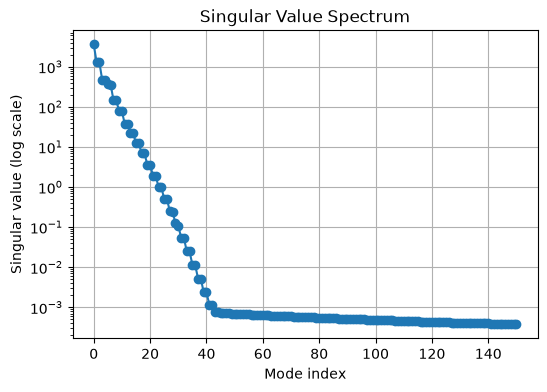

In [ ]:
# Plot of the Singular Value Spectrum
plt.figure(figsize=(6, 4))
plt.semilogy(Shat, "o-")
plt.xlabel("Mode index")
plt.ylabel("Singular value (log scale)")
plt.title("Singular Value Spectrum")
plt.grid(True)
plt.show()

The above plot shows a the singular values on a logscale. Here it can be seen that the most dominent mode is the first and so on through the singular value matrix. As this is on a log scale it is also clear to see that there is quite a large difference in size between the magnitude of the singular values, which indicates that only a few modes can represent most of the flow field. 

In [35]:
# Extracting the leading singular vectors

# Leading LEFT singular vectors
u1 = Uhat[:, 0]
u2 = Uhat[:, 1]

# Leading RIGHT singular vectors
v1 = VThat[0, :]
v2 = VThat[1, :]

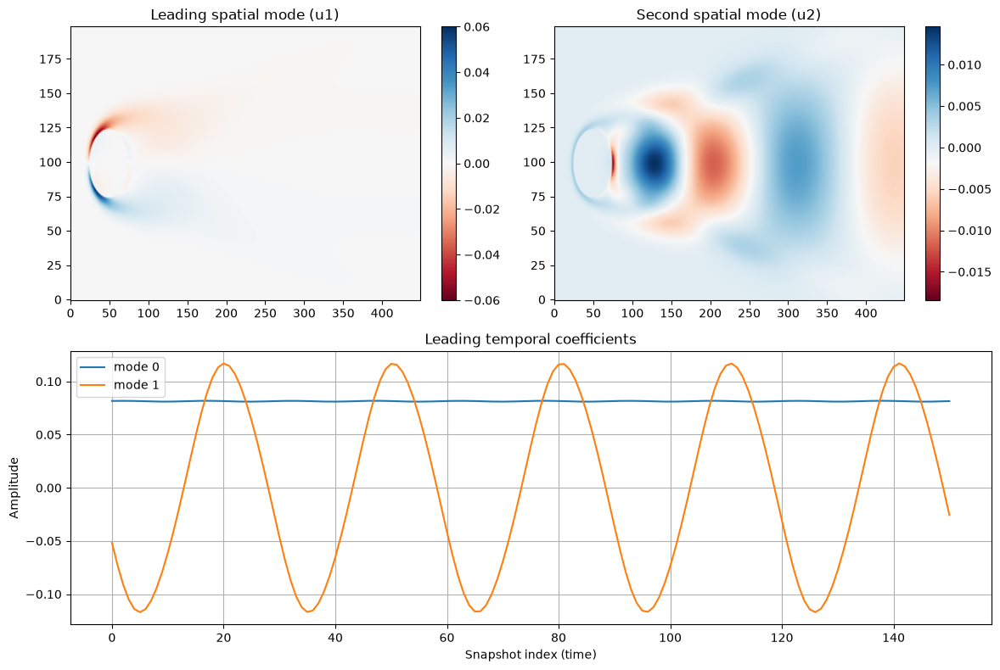

In [ ]:
# Plotting the first 2 modes of the left singular vectors and right singular vectors
fig = plt.figure(figsize=(12, 8))
gs = fig.add_gridspec(2, 2)
ax0 = fig.add_subplot(gs[0, 0])
ax1 = fig.add_subplot(gs[0, 1])
ax2 = fig.add_subplot(gs[1, :])  # spans both columns
mode0 = u1.reshape(ny, nx)
mode1 = u2.reshape(ny, nx)
im0 = ax0.imshow(mode0.T, cmap="RdBu", origin="lower", aspect="auto")
ax0.set_title("Leading spatial mode (u1)")
plt.colorbar(im0, ax=ax0)
im1 = ax1.imshow(mode1.T, cmap="RdBu", origin="lower", aspect="auto")
ax1.set_title("Second spatial mode (u2)")
plt.colorbar(im1, ax=ax1)
ax2.plot(v1, label="mode 0")
ax2.plot(v2, label="mode 1")
ax2.set_xlabel("Snapshot index (time)")
ax2.set_ylabel("Amplitude")
ax2.set_title("Leading temporal coefficients")
ax2.legend()
ax2.grid(True)
plt.tight_layout()
plt.show()


Above the first and the second mode is represented (both right and left singular values). From the left singular vectors the spatial position is represented and from the right singular vectors the time dependecies (how active the mode is) can be found by how high the amplitude is at a given time. The first mode is therefore always present which is why this mode has the highest singular value. 

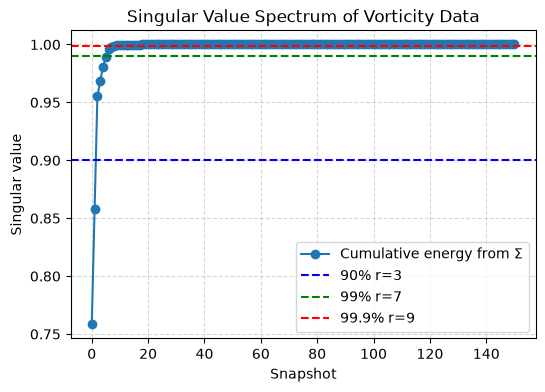

In [ ]:
# Find cumulative energy for plot using Frobenius norm
energy_cum = np.cumsum(Shat**2) / np.sum(Shat**2)

#Find ranks for 90, 99 and 99.9 % of captured flow:
r90 = np.argmax(energy_cum >= 0.90) + 1
r99 = np.argmax(energy_cum >= 0.99) + 1
r999 = np.argmax(energy_cum >= 0.999) + 1

#Print singular value spectrum
plt.figure(figsize=(6, 4))
plt.plot(energy_cum, 'o-', label = r"Cumulative energy from $\Sigma$")
plt.axhline(0.9, color = 'b', linestyle = '--', label=f"90% r={r90}")
plt.axhline(0.99, color = 'g', linestyle = '--', label=f"99% r={r99}")
plt.axhline(0.999, color = 'r', linestyle = '--', label=f"99.9% r={r999}")
plt.xlabel("Snapshot")
plt.ylabel("Singular value")
plt.legend()
plt.title("Singular Value Spectrum of Vorticity Data")
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.show()

It is here seen that to capture 90%, 99% and 99.9% only the first 3, 7 and 9 modes are needed respectively. 

In [69]:
r = [r90, r99, r999]
errorlist = []
xtildelist = []

for i in r:
    xtilde = Uhat[:, :i] @ np.diag(Shat[:i]) @ VThat[:i, :]
    xtildelist.append(xtilde)

    error = np.linalg.norm(VORTALL - xtilde) ** 2
    relativeerror = error / np.linalg.norm(VORTALL) ** 2

    errorlist.append(relativeerror)

print(f"The relative error between the true matrix and the reconstructed matrix,")
for rank, relativeerror in zip(r, errorlist):
    print(f"for rank {rank} is {relativeerror}, and therefore caputures {(1-relativeerror)*100}%")

The relative error between the true matrix and the reconstructed matrix,
for rank 3 is 0.04467633383298935, and therefore caputures 95.53236661670107%
for rank 7 is 0.0034645900215795897, and therefore caputures 99.65354099784204%
for rank 9 is 0.0009515551390945279, and therefore caputures 99.90484448609055%


In [70]:
n_snapshots = xtildelist[0].shape[1]

fig, axes = plt.subplots(
    1, len(r),
    figsize=(5 * len(r), 4),
    squeeze=False
)
axes = axes[0]

ims = []

for ax, xtilde, rank in zip(axes, xtildelist, r):
    frame0 = xtilde[:, 0].reshape(ny, nx)

    im = ax.imshow(
        frame0.T,
        cmap="RdBu",
        origin="lower",
        vmin=-5,
        vmax=5,
        aspect="auto",
    )

    ax.set_title(f"r = {rank}")
    ims.append(im)

fig.suptitle("Snapshot 0")


def update(frame_idx):
    for im, xtilde in zip(ims, xtildelist):
        frame = xtilde[:, frame_idx].reshape(ny, nx)
        im.set_array(frame.T)

    fig.suptitle(f"Snapshot {frame_idx}")
    return ims


ani = animation.FuncAnimation(
    fig,
    update,
    frames=n_snapshots,
    interval=50,
    blit=False,
)

plt.tight_layout()

mpl.rcParams["animation.embed_limit"] = 200   # in MB

display(HTML(ani.to_jshtml()))
plt.close(fig)

From the movies shown above, it can be seen that all captures the overall vortex flow field very well. However in the rank 3 movie it is possible to see that some resolution is lost as it is a bit more blurry than the other two even thought it cuptures 95,5 % of the flow field. It is impossible to capture the difference between the rank 7 and rank 9 movies with the naked eye. 

In [ ]:
# Computing the truncated SVD for r = 10
r = 10

W = np.diag(Shat[:r]) @ VThat[:r, :]
Uhattrunc = Uhat[:, :r]

# Finding where the error is largest between the true snapshot and the reconstructed vortex field using the truncated SVD
errors = np.array([
    np.linalg.norm(VORTALL[:, i] - Uhattrunc @ W[:, i]) ** 2
    / np.linalg.norm(VORTALL[:, i]) ** 2
    for i in range(W.shape[1])
])

largest_index = np.argmax(errors)

print(f"Largest relative error: {errors[largest_index]}")
print(f"This occurs at snapshot: {largest_index + 1}")

Largest relative error: 0.0010150299573902964
This occurs at snapshot: 117


Here it can be seen that for the reconstructed matrix the largest error between the true snapshot and the reconstructed snapshot is only: 0.1%

In [79]:
# Creating two matrices with the 1 through m-1 columns and 2 through m columns respectively
W1 = W[:, :-1]
What = W[:, 1:]

# Generate economy SVD from W1 (1 through m-1 columns)
UhatW, ShatW, VThatW = np.linalg.svd(W1, full_matrices=False)

UhatW_conj = UhatW.conj().T
VhatW = VThatW.conj().T

# Computing the pseudo inverse of W1 using the SVD
pinvW = VhatW @ np.diag(1 / ShatW) @ UhatW_conj
# Slope from SVD
A = What @ pinvW

# Computing the Eigenvalues and Eigenvectors
Eigenvalues, Eigenvectors = np.linalg.eig(A)

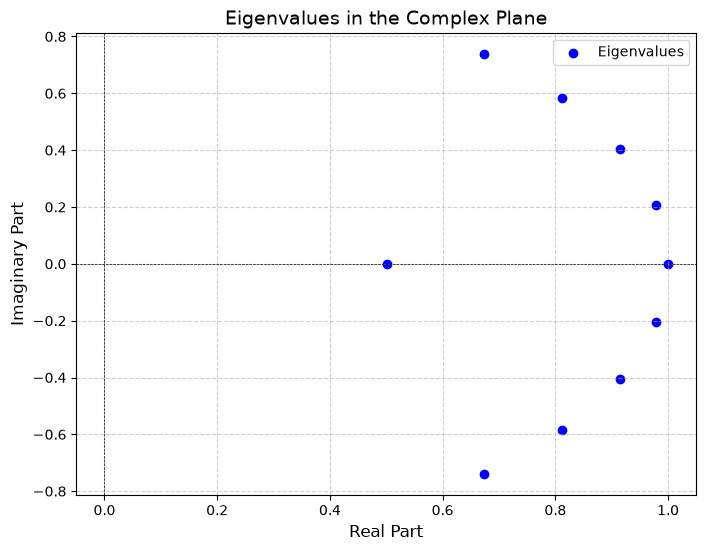

In [81]:
# Plotting the eigenvalues in the complex plane
fig, ax = plt.subplots(figsize=(8, 6))

# Scatter plot of eigenvalues in the complex plane
ax.scatter(Eigenvalues.real, Eigenvalues.imag, color="blue", label="Eigenvalues")

# Add grid, labels, and title
ax.axhline(0, color="black", linewidth=0.5, linestyle="--")  # Horizontal axis
ax.axvline(0, color="black", linewidth=0.5, linestyle="--")  # Vertical axis
ax.set_xlabel("Real Part", fontsize=12)
ax.set_ylabel("Imaginary Part", fontsize=12)
ax.set_title("Eigenvalues in the Complex Plane", fontsize=14)
ax.grid(True, linestyle="--", alpha=0.6)

# Add legend
ax.legend()

plt.show()

In [ ]:
# Using the A matrix to make predictions one state at a time from w1 -> w151
W_pred = np.zeros_like(W)

W_pred[:, 0] = W[:, 0]

for i in range(1, W.shape[1]):
    W_pred[:, i] = A @ W_pred[:, i - 1]
    
# Reconstructing the vortex flow field using the predictions
VORTALL_pred = Uhattrunc @ W_pred

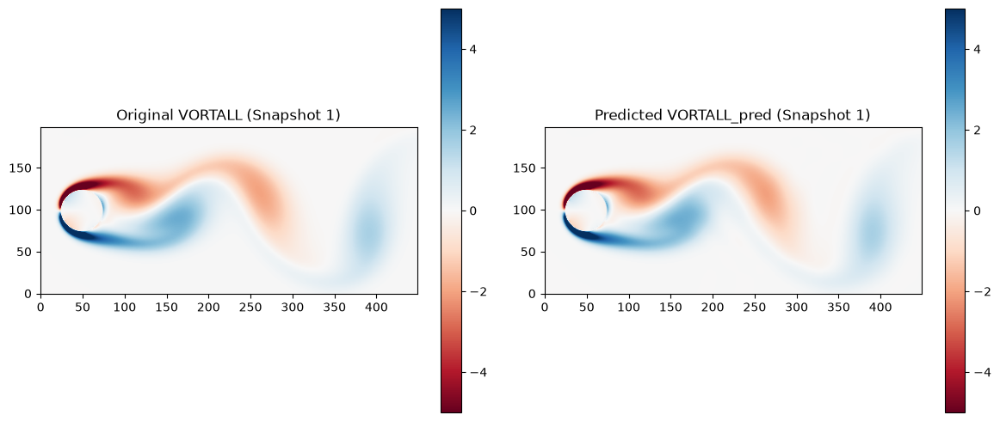

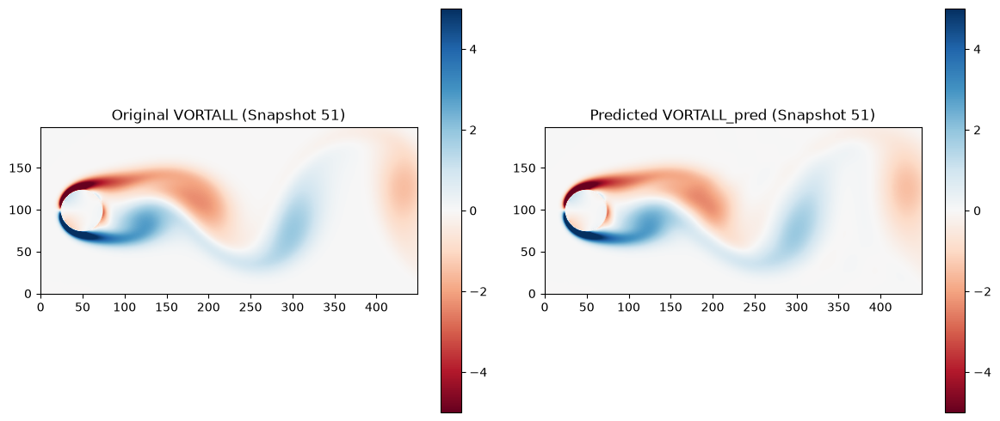

In [91]:
snapshot_idx = 0  # Comparing index 0 i.e. the first snapshot

# Reshape the selected snapshot into the grid (ny x nx)
vort_2d = VORTALL[:, snapshot_idx].reshape(ny, nx)
vort_pred_2d = VORTALL_pred[:, snapshot_idx].reshape(ny, nx)

# Create a figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot the original snapshot
im1 = axes[0].imshow(vort_2d.T, cmap="RdBu", origin="lower", vmin=-5, vmax=5)
axes[0].set_title(f"Original VORTALL (Snapshot {snapshot_idx+1})")
plt.colorbar(im1, ax=axes[0])

# Plot the predicted snapshot
im2 = axes[1].imshow(vort_pred_2d.T, cmap="RdBu", origin="lower", vmin=-5, vmax=5)
axes[1].set_title(f"Predicted VORTALL_pred (Snapshot {snapshot_idx+1})")
plt.colorbar(im2, ax=axes[1])

plt.tight_layout()
plt.show()

snapshot_idx = 50  # Comparing index 0 i.e. the first snapshot

# Reshape the selected snapshot into the grid (ny x nx)
vort_2d = VORTALL[:, snapshot_idx].reshape(ny, nx)
vort_pred_2d = VORTALL_pred[:, snapshot_idx].reshape(ny, nx)

# Create a figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot the original snapshot
im1 = axes[0].imshow(vort_2d.T, cmap="RdBu", origin="lower", vmin=-5, vmax=5)
axes[0].set_title(f"Original VORTALL (Snapshot {snapshot_idx+1})")
plt.colorbar(im1, ax=axes[0])

# Plot the predicted snapshot
im2 = axes[1].imshow(vort_pred_2d.T, cmap="RdBu", origin="lower", vmin=-5, vmax=5)
axes[1].set_title(f"Predicted VORTALL_pred (Snapshot {snapshot_idx+1})")
plt.colorbar(im2, ax=axes[1])

plt.tight_layout()
plt.show()

Here it is again impossible to spot the difference with the naked eye between the original vortex flow field and the predicted vortex flow field. This could in principle also be used to make predictions further into the future, but here we cannot make comparisons between the original and therefore do not know if this is the true future state. To do this one could withhold some information i.e. the last 30 snapshots in the construction of the A matrix, and then compare how well the predictions are on these last 30 withholded snapshots. 